# 04 — SARIMA com Ordem Heurística (Restrição Operacional)

**Dissertação**: Análise Comparativa de Algoritmos de Regressão para Previsão em Séries Temporais  
**Autora**: Luana Gomes de Souza  
**Etapa**: OE2 + OE3 — Modelo estatístico clássico sob restrição operacional

---
### Contexto e justificativa
Este notebook implementa o SARIMA com **ordem fixa por heurística**, cobrindo o cenário de
**restrição operacional** definido na seção 3.2 da dissertação — situação em que não há
tempo ou recursos para busca exaustiva de hiperparâmetros.

A ordem adotada é `SARIMA(1,1,1)(1,1,0)[12]`, justificada por:
- `d=1, D=1`: diferenciação simples e sazonal — padrão para séries mensais com tendência e sazonalidade
- `p=1, q=1`: componentes AR e MA de ordem mínima — parcimônia
- `P=1, Q=0`: componente sazonal AR de ordem 1 — captura periodicidade sem sobre-parametrizar
- `m=12`: sazonalidade mensal

### Complemento
O notebook `04b_sarima_auto.ipynb` implementa a versão com seleção automática de ordem
por AIC — resultado definitivo para a tabela comparativa principal da dissertação.

## 1. Imports e configurações

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import time
import json
from pathlib import Path
from datetime import datetime
from sklearn.metrics import mean_absolute_error, r2_score
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings('ignore')

# ── Caminhos (funciona com cwd em autopred/ ou notebooks/) ───────────────────
import sys

_root = Path.cwd().resolve()
for _candidate in (_root, *_root.parents):
    if (_candidate / 'src' / 'paths.py').is_file():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from src.paths import DATA_DIR, PROJECT_ROOT, RESULT_DIR

RESULT_DIR.mkdir(parents=True, exist_ok=True)

_required = {
    'Monthly-train.csv': DATA_DIR / 'Monthly-train.csv',
    'Monthly-test.csv':  DATA_DIR / 'Monthly-test.csv',
}
_missing = [name for name, p in _required.items() if not p.is_file()]
if _missing:
    raise FileNotFoundError(
        f'Arquivos não encontrados em {DATA_DIR}: {_missing}\n'
        f'PROJECT_ROOT = {PROJECT_ROOT}'
    )
print(f'PROJECT_ROOT = {PROJECT_ROOT}')
print(f'DATA_DIR       = {DATA_DIR}  OK')
print(f'RESULT_DIR     = {RESULT_DIR}')

SEED      = 42
H         = 18
MIN_TRAIN = 24
N_ORIGINS = 3
PILOT_N   = 200

# ── Ordem heurística fixa ─────────────────────────────────────────────────────
# SARIMA(p,d,q)(P,D,Q)[m]
ORDER         = (1, 1, 1)    # parte não-sazonal
SEASONAL_ORDER = (1, 1, 0, 12)  # parte sazonal

# Limite de tempo por série (restrição operacional — seção 3.2)
# Séries que ultrapassarem esse limite serão marcadas como TIMEOUT
TIME_LIMIT_S = 30.0

np.random.seed(SEED)
print('Configuração carregada OK')
print(f'  Ordem SARIMA : {ORDER}{SEASONAL_ORDER}')
print(f'  Limite tempo : {TIME_LIMIT_S}s por série')

PROJECT_ROOT = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred
DATA_DIR       = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\data\raw  OK
RESULT_DIR     = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\results
Configuração carregada OK
  Ordem SARIMA : (1, 1, 1)(1, 1, 0, 12)
  Limite tempo : 30.0s por série


## 2. Funções base (pipeline padrão)

In [2]:
def load_m4_monthly(data_dir):
    train_raw = pd.read_csv(data_dir / 'Monthly-train.csv')
    test_raw  = pd.read_csv(data_dir / 'Monthly-test.csv')
    def wide_to_long(df):
        id_col = df.columns[0]
        melted = df.melt(id_vars=id_col, value_vars=df.columns[1:],
                         var_name='step_raw', value_name='y')
        melted = melted.rename(columns={id_col: 'unique_id'})
        melted['step'] = melted['step_raw'].str.extract(r'(\d+)').astype(int)
        melted = melted.drop(columns='step_raw').dropna(subset=['y'])
        return melted.sort_values(['unique_id','step']).reset_index(drop=True)
    return wide_to_long(train_raw), wide_to_long(test_raw)

def make_rolling_windows(series, horizon, min_train, n_origins):
    n = len(series)
    if n < min_train + horizon:
        return []
    last_origin  = n - horizon
    first_origin = min_train
    if last_origin <= first_origin:
        return []
    origins = np.linspace(first_origin, last_origin, n_origins, dtype=int).tolist()
    origins = sorted(set(origins))
    return [
        {'origin': o, 'train': series[:o], 'test': series[o:o+horizon]}
        for o in origins if len(series[o:o+horizon]) == horizon
    ]

def calc_mape(y_true, y_pred):
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return float(np.mean(np.abs((y_true[mask]-y_pred[mask])/y_true[mask]))*100)

def calc_metrics(y_true, y_pred):
    return {
        'mape': calc_mape(y_true, y_pred),
        'mae' : float(mean_absolute_error(y_true, y_pred)),
        'r2'  : float(r2_score(y_true, y_pred))
    }

print('Funções base OK')

Funções base OK


## 3. Carregamento e piloto

In [3]:
train_df, test_df = load_m4_monthly(DATA_DIR)
rng       = np.random.default_rng(SEED)
pilot_ids = rng.choice(train_df['unique_id'].unique(), size=PILOT_N, replace=False)
train_pilot = train_df[train_df['unique_id'].isin(pilot_ids)].copy()
print(f'Piloto: {PILOT_N} séries | {len(train_pilot):,} linhas')

Piloto: 200 séries | 44,224 linhas


## 4. Modelo SARIMA heurístico

O pipeline SARIMA tem três camadas de proteção para garantir **continuidade operacional** (seção 3.1):
1. **Timeout por série**: se o ajuste demorar mais que `TIME_LIMIT_S`, a janela é marcada como `TIMEOUT`
2. **Fallback por exceção**: erros de convergência são registrados como `ERROR` sem travar o pipeline
3. **Registro completo**: toda falha é rastreada com motivo para análise posterior

In [4]:
import signal
import platform

# Timeout via signal só funciona em Unix/Mac.
# No Windows usamos controle por tempo wall-clock (sem interrupção forçada).
USE_SIGNAL = platform.system() != 'Windows'

if USE_SIGNAL:
    class TimeoutError(Exception):
        pass
    def _timeout_handler(signum, frame):
        raise TimeoutError()


def sarima_heuristic(train, horizon,
                     order=ORDER,
                     seasonal_order=SEASONAL_ORDER,
                     time_limit=TIME_LIMIT_S):
    """
    SARIMA com ordem fixa heurística e controle de timeout.
    Retorna array de previsões ou levanta exceção em caso de falha.
    """
    t0 = time.perf_counter()

    model = SARIMAX(
        train,
        order          = order,
        seasonal_order = seasonal_order,
        enforce_stationarity  = False,
        enforce_invertibility = False
    )
    fit = model.fit(disp=False, maxiter=50)

    # Verificação de timeout por wall-clock (Windows-safe)
    if time.perf_counter() - t0 > time_limit:
        raise TimeoutError(f'Ajuste ultrapassou {time_limit}s')

    fc = fit.forecast(steps=horizon)
    return np.array(fc)


# Teste rápido com série sintética
np.random.seed(SEED)
ex = np.tile([100,105,110,115,120,125,120,115,110,105,100,95], 4).astype(float)
ex += np.random.normal(0, 3, len(ex))

t0   = time.time()
pred = sarima_heuristic(ex, horizon=H)
print(f'Teste OK em {time.time()-t0:.2f}s')
print(f'Previsão (3 primeiros): {pred[:3].round(2)}')

Teste OK em 0.34s
Previsão (3 primeiros): [ 97.73 102.7  106.17]


## 5. Pipeline com rastreamento de falhas

In [5]:
def run_sarima_pipeline(train_df, horizon, min_train, n_origins,
                        model_name, predict_fn, time_limit):
    """
    Pipeline com rastreamento detalhado de falhas — essencial para
    análise de continuidade operacional (seção 3.1 da dissertação).
    """
    records = []
    ids     = train_df['unique_id'].unique()
    total   = len(ids)

    for i, uid in enumerate(ids):
        if (i+1) % 50 == 0 or i == 0:
            print(f'  [{i+1}/{total}] {uid}...')

        values  = train_df[train_df['unique_id']==uid]['y'].values.astype(float)
        windows = make_rolling_windows(values, horizon, min_train, n_origins)

        if not windows:
            records.append({
                'unique_id':uid, 'model':model_name,
                'origin':None, 'n_train':None,
                'mape':None, 'mae':None, 'r2':None,
                'exec_time_s':None, 'status':'SKIP_SHORT'
            })
            continue

        for win in windows:
            t0 = time.perf_counter()
            try:
                pred    = predict_fn(win['train'], horizon)
                elapsed = time.perf_counter() - t0

                # Verifica timeout após retorno (Windows-safe)
                if elapsed > time_limit:
                    status  = f'TIMEOUT ({elapsed:.1f}s)'
                    metrics = {'mape':None,'mae':None,'r2':None}
                else:
                    metrics = calc_metrics(win['test'], pred)
                    status  = 'OK'

            except Exception as e:
                elapsed = time.perf_counter() - t0
                metrics = {'mape':None,'mae':None,'r2':None}
                status  = f'ERROR: {str(e)[:80]}'

            records.append({
                'unique_id'  : uid,
                'model'      : model_name,
                'origin'     : win['origin'],
                'n_train'    : len(win['train']),
                **metrics,
                'exec_time_s': elapsed,
                'status'     : status
            })

    return pd.DataFrame(records)

print('Pipeline SARIMA definido OK')

Pipeline SARIMA definido OK


## 6. Execução

> **Tempo esperado**: 5–20 minutos para 200 séries (3 janelas cada).  
> O progresso é impresso a cada 50 séries.

In [6]:
print(f'Rodando SARIMA heurístico em {PILOT_N} séries...')
print(f'Ordem: {ORDER}{SEASONAL_ORDER} | Limite: {TIME_LIMIT_S}s/série\n')

t_start = time.time()

results_sarima = run_sarima_pipeline(
    train_df   = train_pilot,
    horizon    = H,
    min_train  = MIN_TRAIN,
    n_origins  = N_ORIGINS,
    model_name = 'sarima_heuristic',
    predict_fn = sarima_heuristic,
    time_limit = TIME_LIMIT_S
)

elapsed_total = time.time() - t_start
print(f'\nConcluído em {elapsed_total/60:.1f} minutos')

Rodando SARIMA heurístico em 200 séries...
Ordem: (1, 1, 1)(1, 1, 0, 12) | Limite: 30.0s/série

  [1/200] M10314...
  [50/200] M22140...
  [100/200] M31532...
  [150/200] M42723...
  [200/200] M9906...

Concluído em 1.0 minutos


## 7. Análise de falhas — continuidade operacional

In [7]:
# Distribuição de status
status_counts = results_sarima['status'].value_counts()
print('=== Distribuição de status ===')
print(status_counts.to_string())

ok_sarima      = results_sarima[results_sarima['status'] == 'OK']
timeout_sarima = results_sarima[results_sarima['status'].str.startswith('TIMEOUT', na=False)]
error_sarima   = results_sarima[results_sarima['status'].str.startswith('ERROR', na=False)]
skip_sarima    = results_sarima[results_sarima['status'] == 'SKIP_SHORT']

n_tentativas = results_sarima['origin'].notna().sum()
taxa_sucesso = 100 * len(ok_sarima) / n_tentativas if n_tentativas > 0 else 0

print(f'\n=== Continuidade operacional (seção 3.1) ===')
print(f'  Total tentativas : {n_tentativas}')
print(f'  OK               : {len(ok_sarima)} ({taxa_sucesso:.1f}%)')
print(f'  Timeout          : {len(timeout_sarima)}')
print(f'  Erro             : {len(error_sarima)}')
print(f'  Skip (curta)     : {len(skip_sarima)}')

# Tempo de execução por janela
exec_times = results_sarima[results_sarima['origin'].notna()]['exec_time_s']
print(f'\n=== Tempo de execução por janela ===')
print(f'  Mediana : {exec_times.median():.3f}s')
print(f'  P95     : {exec_times.quantile(0.95):.3f}s')
print(f'  Máximo  : {exec_times.max():.3f}s')

=== Distribuição de status ===
status
OK    600

=== Continuidade operacional (seção 3.1) ===
  Total tentativas : 600
  OK               : 600 (100.0%)
  Timeout          : 0
  Erro             : 0
  Skip (curta)     : 0

=== Tempo de execução por janela ===
  Mediana : 0.091s
  P95     : 0.255s
  Máximo  : 0.612s


## 8. Resultados e comparação acumulada

In [8]:
by_series_sarima = (
    ok_sarima.groupby('unique_id')[['mape','mae','r2','exec_time_s']]
    .median().reset_index()
)

print('=== Desempenho SARIMA heurístico ===')
print(f'  MAPE mediano = {by_series_sarima["mape"].median():.4f}%')
print(f'  MAE  mediano = {by_series_sarima["mae"].median():.4f}')
print(f'  R²   mediano = {by_series_sarima["r2"].median():.4f}')
print(f'  Tempo mediano= {by_series_sarima["exec_time_s"].median():.4f}s')

# Carrega resultados anteriores
prev_path = RESULT_DIR / 'tabela_acumulada_nb03_ses.csv'
if prev_path.exists():
    prev = pd.read_csv(prev_path, index_col=0)
    sarima_row = pd.DataFrame([{
        'MAPE (%)' : round(by_series_sarima['mape'].median(), 4),
        'MAE'      : round(by_series_sarima['mae'].median(),  4),
        'R²'       : round(by_series_sarima['r2'].median(),   4),
        'Tempo (s)': round(by_series_sarima['exec_time_s'].median(), 4),
    }], index=['SARIMA heurístico'])
    summary = pd.concat([prev, sarima_row]).sort_values('MAPE (%)')
else:
    print('Arquivo anterior não encontrado — mostrando só SARIMA')
    summary = pd.DataFrame([{
        'MAPE (%)' : round(by_series_sarima['mape'].median(), 4),
        'MAE'      : round(by_series_sarima['mae'].median(),  4),
        'R²'       : round(by_series_sarima['r2'].median(),   4),
        'Tempo (s)': round(by_series_sarima['exec_time_s'].median(), 4),
    }], index=['SARIMA heurístico'])

print('\n=== Comparação acumulada — todos os modelos até agora ===')
print(summary.to_string())
summary.to_csv(RESULT_DIR / 'tabela_acumulada_nb04_sarima_heuristic.csv')

=== Desempenho SARIMA heurístico ===
  MAPE mediano = 10.0628%
  MAE  mediano = 284.7858
  R²   mediano = -2.0551
  Tempo mediano= 0.0990s

=== Comparação acumulada — todos os modelos até agora ===
                   MAPE (%)       MAE      R²  Tempo (s)
Holt-Winters         8.2606  256.0183 -1.0642     0.1852
Persistência         8.6992  274.1667 -1.2684     0.0004
SES                  8.7764  253.5196 -1.1898     0.0038
SARIMA heurístico   10.0628  284.7858 -2.0551     0.0990
Sazonal ingênuo     11.0601  316.8889 -2.1744     0.0004
Média histórica     18.5971  589.9421 -6.4779     0.0004


## 9. Gráfico — distribuição de tempo de execução

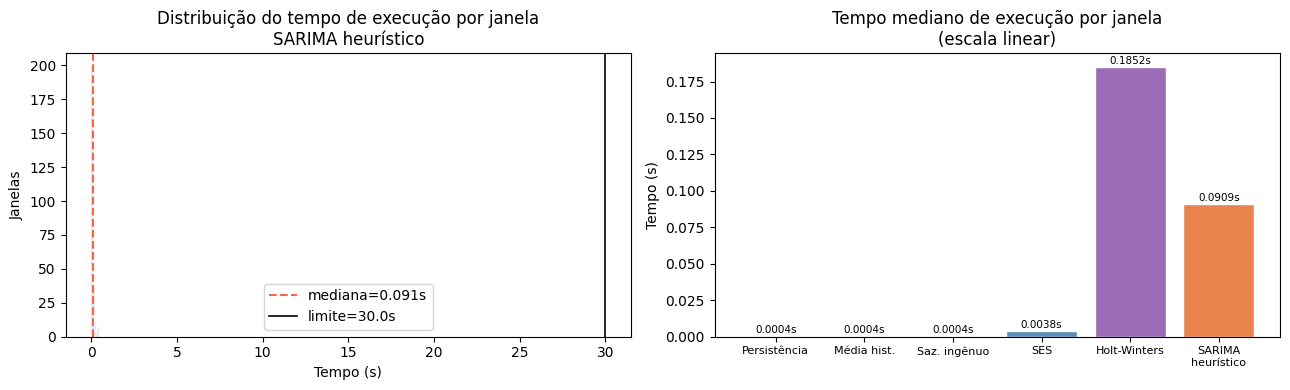

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histograma de tempo
tempos = ok_sarima['exec_time_s']
axes[0].hist(tempos.clip(upper=tempos.quantile(0.99)), bins=40,
             color='steelblue', edgecolor='white', linewidth=0.5)
axes[0].axvline(tempos.median(), color='tomato', linestyle='--',
                linewidth=1.5, label=f'mediana={tempos.median():.3f}s')
axes[0].axvline(TIME_LIMIT_S, color='black', linestyle='-',
                linewidth=1.2, label=f'limite={TIME_LIMIT_S}s')
axes[0].set_title('Distribuição do tempo de execução por janela\nSARIMA heurístico')
axes[0].set_xlabel('Tempo (s)')
axes[0].set_ylabel('Janelas')
axes[0].legend()

# Comparação de tempo entre modelos
tempos_modelos = {
    'Persistência'  : 0.0004,
    'Média hist.'   : 0.0004,
    'Saz. ingênuo'  : 0.0004,
    'SES'           : 0.0038,
    'Holt-Winters'  : 0.1852,
    'SARIMA\nheurístico': tempos.median(),
}
nomes  = list(tempos_modelos.keys())
values = list(tempos_modelos.values())
colors = ['#6BAE75','#6BAE75','#6BAE75','#5B8DB8','#9B6BB5','#E8834E']

bars = axes[1].bar(nomes, values, color=colors, edgecolor='white')
axes[1].set_title('Tempo mediano de execução por janela\n(escala linear)')
axes[1].set_ylabel('Tempo (s)')
axes[1].tick_params(axis='x', labelsize=8)
for bar, v in zip(bars, values):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + max(values)*0.01,
                 f'{v:.4f}s', ha='center', fontsize=7.5)

plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_sarima_heuristic_tempo.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Gráfico — MAPE: SARIMA heurístico vs modelos anteriores

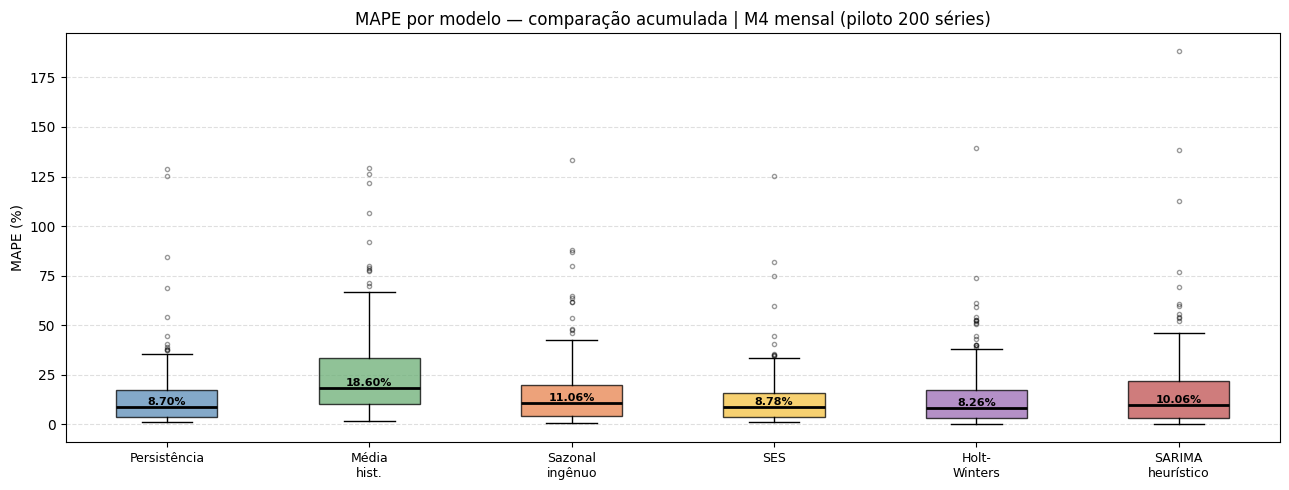

In [10]:
# Carrega dados por série dos modelos anteriores para boxplot comparativo
dfs_anteriores = []
for fname, model_label in [
    ('results_nb02_by_series.csv', None),
    ('results_ses_by_series.csv',  'ses'),
]:
    path = RESULT_DIR / fname
    if path.exists():
        df = pd.read_csv(path)
        if 'model' not in df.columns and model_label:
            df['model'] = model_label
        dfs_anteriores.append(df)

sarima_df = by_series_sarima.copy()
sarima_df['model'] = 'sarima_heuristic'

if dfs_anteriores:
    all_df = pd.concat(dfs_anteriores + [sarima_df], ignore_index=True)
else:
    all_df = sarima_df

order_plot = ['persistence','mean','seasonal_naive','ses','holt_winters','sarima_heuristic']
name_map   = {
    'persistence'     : 'Persistência',
    'mean'            : 'Média\nhist.',
    'seasonal_naive'  : 'Sazonal\ningênuo',
    'ses'             : 'SES',
    'holt_winters'    : 'Holt-\nWinters',
    'sarima_heuristic': 'SARIMA\nheurístico',
}
colors_plot = ['#5B8DB8','#6BAE75','#E8834E','#F5C242','#9B6BB5','#C05050']

order_present = [m for m in order_plot if m in all_df['model'].unique()]

fig, ax = plt.subplots(figsize=(13, 5))
data_list = [
    all_df[all_df['model']==m]['mape'].dropna()
    for m in order_present
]
bp = ax.boxplot(
    data_list,
    patch_artist=True,
    medianprops=dict(color='black', linewidth=2),
    flierprops=dict(marker='o', markersize=3, alpha=0.4),
    showfliers=True
)
for patch, color in zip(bp['boxes'], colors_plot[:len(order_present)]):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

ax.set_xticks(range(1, len(order_present)+1))
ax.set_xticklabels([name_map[m] for m in order_present], fontsize=9)
ax.set_ylabel('MAPE (%)')
ax.set_title('MAPE por modelo — comparação acumulada | M4 mensal (piloto 200 séries)')
ax.grid(axis='y', linestyle='--', alpha=0.4)

for i, d in enumerate(data_list):
    ax.text(i+1, d.median(), f'{d.median():.2f}%',
            ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_mape_acumulado_nb04.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Salvando artefatos

In [11]:
results_sarima.to_csv(RESULT_DIR / 'results_sarima_heuristic_by_window.csv', index=False)
sarima_df.to_csv(RESULT_DIR / 'results_sarima_heuristic_by_series.csv', index=False)

run_log = {
    'timestamp'      : datetime.now().isoformat(),
    'notebook'       : '04_sarima_heuristic',
    'model'          : 'sarima_heuristic',
    'order'          : list(ORDER),
    'seasonal_order' : list(SEASONAL_ORDER),
    'time_limit_s'   : TIME_LIMIT_S,
    'dataset'        : 'M4_Monthly',
    'pilot_n'        : PILOT_N,
    'seed'           : SEED,
    'horizon_H'      : H,
    'n_ok'           : int(len(ok_sarima)),
    'n_timeout'      : int(len(timeout_sarima)),
    'n_errors'       : int(len(error_sarima)),
    'taxa_sucesso'   : round(taxa_sucesso, 2),
    'mape_median'    : round(float(by_series_sarima['mape'].median()), 4),
    'mae_median'     : round(float(by_series_sarima['mae'].median()),  4),
    'r2_median'      : round(float(by_series_sarima['r2'].median()),   4),
    'time_median_s'  : round(float(by_series_sarima['exec_time_s'].median()), 4),
    'elapsed_total_min': round(elapsed_total/60, 2),
}

with open(RESULT_DIR / 'run_log_sarima_heuristic.json', 'w') as f:
    json.dump(run_log, f, indent=2)

print('Artefatos salvos:')
print('  results_sarima_heuristic_by_window.csv')
print('  results_sarima_heuristic_by_series.csv')
print('  run_log_sarima_heuristic.json')
print()
print(json.dumps(run_log, indent=2))

Artefatos salvos:
  results_sarima_heuristic_by_window.csv
  results_sarima_heuristic_by_series.csv
  run_log_sarima_heuristic.json

{
  "timestamp": "2026-05-22T16:26:41.643098",
  "notebook": "04_sarima_heuristic",
  "model": "sarima_heuristic",
  "order": [
    1,
    1,
    1
  ],
  "seasonal_order": [
    1,
    1,
    0,
    12
  ],
  "time_limit_s": 30.0,
  "dataset": "M4_Monthly",
  "pilot_n": 200,
  "seed": 42,
  "horizon_H": 18,
  "n_ok": 600,
  "n_timeout": 0,
  "n_errors": 0,
  "taxa_sucesso": 100.0,
  "mape_median": 10.0628,
  "mae_median": 284.7858,
  "r2_median": -2.0551,
  "time_median_s": 0.099,
  "elapsed_total_min": 0.95
}


## 12. Resumo e próximos passos

---

### Papel deste notebook na dissertação

Este notebook documenta o **SARIMA sob restrição operacional** — cenário em que o tempo
disponível para ajuste impede a busca exaustiva de hiperparâmetros. Os resultados aqui
representam o **limite inferior do SARIMA** (pior caso controlado), enquanto o notebook
`04b_sarima_auto.ipynb` documentará o **limite superior** (melhor caso possível com
seleção automática de ordem).

A diferença entre os dois resultados quantifica o **custo da restrição operacional** —
dado direto para a seção 5.2 da dissertação (condições de comparação justa).

---

### Próximo notebook: `04b_sarima_auto.ipynb`
- Seleção automática de ordem por AIC
- **Rodar overnight** — pode demorar várias horas
- Resultado definitivo para a tabela comparativa principal